# 4.3 Estabilidad de Lyapunov

Una función $V(x)$ positiva definida cuya derivada $\dot V$ es negativa definida demuestra estabilidad asintótica del equilibrio en una región. Para $\dot x=Ax$, puede buscarse $V=x^TPx$ resolviendo $A^TP+PA=-Q$ con $Q$ positiva definida.

Si $P$ también es positiva definida, la prueba es global para este modelo lineal autónomo. Aquí usamos $A=\operatorname{diag}(-1,-2)$ y $Q=I$.

**Objetivo:** comprobar las condiciones algebraicas, no solo observar una gráfica.

P = [[0.5  0.  ]
 [0.   0.25]]
Autovalores de P: [0.25 0.5 ]
Residuo AᵀP + PA + Q: 0.0


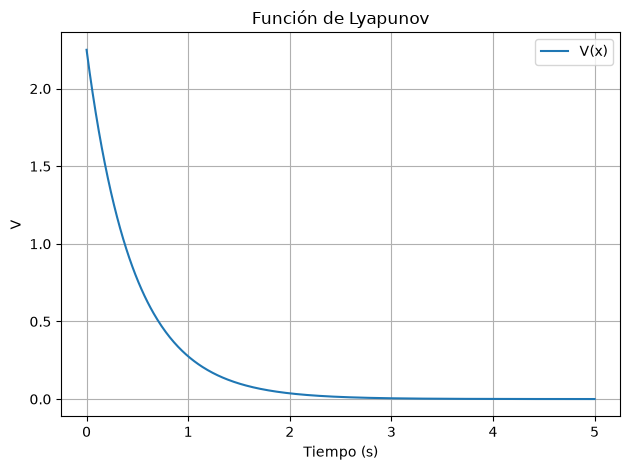

In [1]:
%matplotlib inline
import numpy as np
from scipy.linalg import solve_continuous_lyapunov
from sistemas_dinamicos import graficar, integrar

A = np.diag([-1.0, -2.0])
Q = np.eye(2)
P = solve_continuous_lyapunov(A.T, -Q)
print("P =", P)
print("Autovalores de P:", np.linalg.eigvalsh(P))
print("Residuo AᵀP + PA + Q:", np.linalg.norm(A.T @ P + P @ A + Q))
t = np.linspace(0, 5, 501)
estados = integrar(lambda t, x: A @ x, t, [2, 1])
V = np.einsum("ni,ij,nj->n", estados, P, estados)
graficar(t, {"V(x)": V}, titulo="Función de Lyapunov", ylabel="V");


Los autovalores positivos de $P$ verifican que $V$ es positiva definida, y $\dot V=-x^TQx<0$ fuera del origen. El residuo numérico debe ser cercano a cero.

**Practica:** usa $A=\operatorname{diag}(1,-2)$ y comprueba por qué la solución resultante no proporciona una función positiva definida.